---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 11, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Solve the two exercises in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember to answer any discussion points asked in the question to obtain maximum points.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises and answer the questions.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

## Short questions
1. Name the root-finding methods we have discussed during the lectures, and rank them by their precision. Do all methods always converge? (**2 points**)
2. What is the difference between the trapezoid rule and the Simpson's rule in the Newton-Cotes numerical integration? (**2 points**)
3. What is the simplest way of expanding 1D interpolation methods to 2D? (**2 points**) 
4. What is LU decomposition and why is it used when solving sets of linear algebraic equations? (**2 points**)
5. What is the Jacobian matrix in the Newton-Raphson Method for nonlinear systems of equations? Can the Newton-Raphson method always find a solution for a nonlinear system of equations? (**2 points**)

## answers
1 Bisection, secant, Newton rapson, False position,  
in order of presicion 1NR, 2Bisection, (although could also be pther way arround as NR also requires analytical derivatives) 3secant, 4FP
typically bisection always converges, wherease the others can have issues, depending on the intervals and starting positions, False position is a bracketing method which can have issues depending on starting points, bisection konvergence depends on starting values, NR should find the root but depending on starting value could be slower than bisection

2 Trapezoid rule aproximates the integral using trapezes with h lengths and f(x) - f(x_0) as a and b, Simpsons approximates the integral using quadratic polynomials (which are all in based of the same distance h)


3 Extending 1D interpolation to 2D: Use tensor-product interpolation: interpolate in one dimension and then the other. The simplest example is bilinear interpolation on a rectangular grid.

4 LU decomposition is a method that uses matrizes to solve systems of equation, Ax = b, A being a matrix, and then using lower triangular and upper triangular forms of matrixes we can solve for Ly=b and Ux=y, this is efficient when solving for multiple right-hand sides using the same matrix

5 The Jacobian (NR) contains all the first partial derivatives of the system’s equations and with each iteration solves $J(x_k)\Delta x=-F(x_k)$, then updates $x_{k+1}=x_k+\Delta x$. It cannot always find a solution: convergence is not guaranteed, for example if the initial guess is unsuitable, the Jacobian is singular, or no solution exists.

## Exercise 1. Interpolating the luminosity profile of a galaxy (10 Points)

Imagine an elliptical galaxy with the light intensity profile described by the de Vaucouleurs's law. We have observed four datapoints for the intensity in units of $L_\odot/pc^2$ at the corresponding radii in pc:

\begin{aligned}
(R_0,I_0) &= (0,\;2.14\times10^5),\\
(R_1,I_1) &= (1000,\;1.14\times10^3),\\
(R_2,I_2) &= (1500,\;5.51\times10^2),\\
(R_3,I_3) &= (2000,\;3.36\times10^2).
\end{aligned}


Use the Lagrange polynomial interpolation to fit a polynomial to these datapoints.

**(a)** What is the highest polynomial degree that you can fit to the four datapoints? (**1 point**)

**(b)** Interpolate the datapoints using your polynomial (**5 points** if you use your own Lagrange polynomial, **1 point** if you use embedded python fucntions).

**(c)** Use embedded functions for numerical integration such as **quad** or **simpson** to integrate your Lagrange polynomial that represents your luminosity profile from zero to 2000 pc to obtain the approximate luminosity of the galaxy in $L_\odot$. Use the print command to show the result (**2 points**)

**(d)** Plot your results: the four datapoints and the polynomial that you used to interpolate the function (**2 points**)


## asnwers

(a)
Four distinct radii determine a unique polynomial of maximum degree $4-1=\mathbf{3}$.

(b)
The interpolating polynomial is

$P(R)=214000-459.261333333R+0.316588R^2-0.0000701866667R^3$

It passes through all four data points. This cell builds it with the Lagrange formula, integrates it, and plots it

(c)
The literal integral requested is approximately 72,965,333.33. Since the given intensity is in $L_\odot/\mathrm{pc}^2$, that integral has units $L_\odot/\mathrm{pc}$, not luminosity. For a circularly symmetric galaxy, integrating over annuli gives an approximate total luminosity of 128,556,763,911.70 $L_\odot$.
(d)
The code plots the four datapoints together with the interpolating polynomial.

Integral of P(R) from 0 to 2000 pc: 72965333.33 L_sun/pc
Total luminosity (circular symmetry): 128556763911.70 L_sun


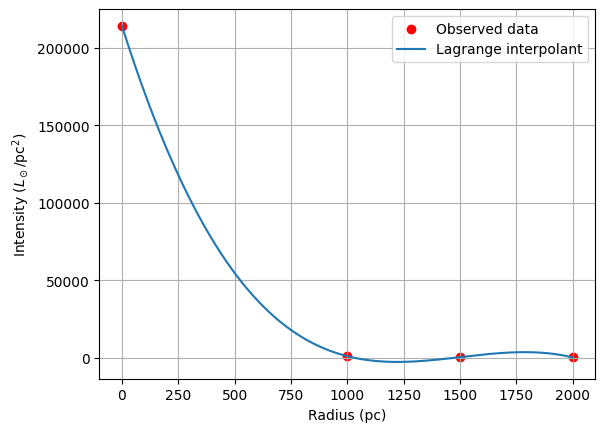

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
R = np.array([0, 1000, 1500, 2000], dtype=float)
I = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2], dtype=float)

def lagrange(r):
    total = 0.0
    for i in range(len(R)):
        basis = 1.0
        for j in range(len(R)):
            if i != j:
                basis *= (r - R[j]) / (R[i] - R[j])
        total += I[i] * basis
    return total

R_plot = np.linspace(0, 2000, 500)
I_plot = np.array([lagrange(r) for r in R_plot])

# Literal integral
integral, error = quad(lagrange, 0, 2000)
print(f"Integral of P(R) from 0 to 2000 pc: {integral:.2f} L_sun/pc")

# Total luminosity for circ sym profile
luminosity, error = quad(lambda r: 2 * np.pi * r * lagrange(r), 0, 2000)
print(f"Total luminosity (circular symmetry): {luminosity:.2f} L_sun")

plt.scatter(R, I, color="red", label="Observed data")
plt.plot(R_plot, I_plot, label="Lagrange interpolant")
plt.xlabel("Radius (pc)")
plt.ylabel(r"Intensity ($L_\odot/\mathrm{pc}^2$)")
plt.legend()
plt.grid(True)
plt.show()



## Exercise 2. Decelerating satellite and numerical derivation (10 Points)

A small spacecraft is decelerating. It's time-dependent coordinate is given by the following equation (the time is in seconds and the distance is in meters):

$$x(t) = 100 - 50 \exp (-0.2t)$$

**(a)** Determine the spacecraft's speed at $t=5$ s using the forward and central finite-difference methods (the non-symmetrical and symmetrical methods of calculating the numerical derivative) for the $dt = 1$ s (**2 points**)

**(b)** Investigate the accuracy of both methods for different step sizes. Create an array of step sizes ranging from 0.1 s to 2 s and calculate the derivatives for each $dt$ (**2 points**). Compare to the precise analytical formula for speed at $t=5$ s (**2 points**)

**(c)** Plot your results from **(b)** (**2 points**)

**(d)** Which method is more accurate, the central method or the forward method? (**1 point**). Why is one method more accurate than the other from the mathematical point of view (one sentence explanation is enough; **1 point**)



## answers exercise 2
(a) Finite differences at (t=5) s with (dt=1) s
Using

$v_{\text{forward}}=\frac{x(5+dt)-x(5)}{dt}$

$v_{\text{central}}=\frac{x(5+dt)-x(5-dt)}{2dt}$

results:

Forward: 3.33426 m/s

Central: 3.70337 m/s

(b) Compare step sizes and plot
The analytical velocity is $v(t)=10e^{-0.2t}$, so $v(5)=3.67879\ \mathrm{m/s}$. This cell calculates both numerical estimates over (dt=0.1) to 2 s, prints their errors for dt=1 s, and plots estimates and absolute errors

(c)
down below

(d) Which method is more accurate, and why?
The central difference, truncation error is proportional to dt^2 compared to just dt. For dt=1 s, their absolute errors are about 0.02457 and 0.34453

actual derivative 3.6787944117144233
Forward difference dt=1 3.3342614629620186
Central difference dt=1 3.7033688051254856


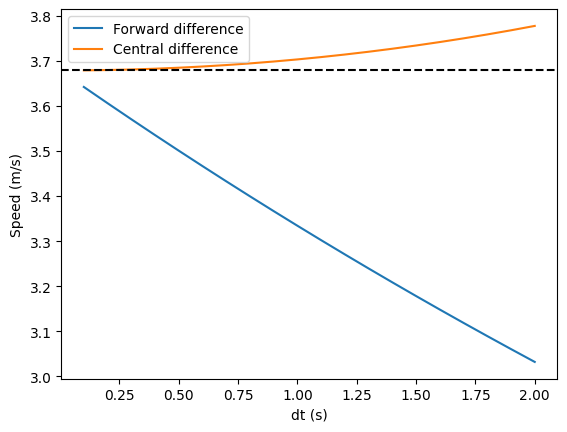

In [53]:
import numpy as np
import matplotlib.pyplot as plt

def x(t):
    return 100 - 50 * np.exp(-0.2 * t)
def dx(t):
    return 10 * np.exp(-0.2 * t)

t = 5
dt = np.arange(0.1, 2.1, 0.1)

forward = [] #empty lists to append
central = []

for h in dt:
    forward.append((x(t + h) - x(t)) / h) #derivatives
    central.append((x(t + h) - x(t - h)) / (2 * h))

exact = dx(t)

print("actual derivative", exact)
print("Forward difference dt=1", (x(t + 1) - x(t)) / 1)
print("Central difference dt=1", (x(t + 1) - x(t - 1)) / 2)

plt.plot(dt, forward, label="Forward difference")
plt.plot(dt, central, label="Central difference")
plt.axhline(exact, color="black", linestyle="--")
plt.xlabel("dt (s)")
plt.ylabel("Speed (m/s)")
plt.legend()
plt.show()